# 04 · EDA - Exploratory Data Analysis

## 0. Chuẩn bị dữ liệu

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_cleaned = pd.read_csv("../data/cleaned/olist_clean.csv")

print("Shape cleaned:", file_cleaned.shape)


Shape cleaned: (108937, 27)


### Nhận xét

- Đọc thành công bảng dữ liệu sau Cleaning.
- Dữ liệu gồm **108.937 dòng và 27 cột**, khớp số liệu Cleaning của nhóm.
- Sử dụng bảng này làm đầu vào chính cho EDA.

**Kết luận:** Dữ liệu đã được tải thành công. Tiếp tục kiểm tra cấu trúc và chất lượng trước khi phân tích.

## 1. Xác minh dữ liệu sau Cleaning ##

### 1.1. Kiểm tra cấu trúc dữ liệu

**Mục tiêu:** Xác định tên cột và kiểu dữ liệu của bảng sau Cleaning.

In [18]:
df1_1 = file_cleaned.dtypes.reset_index()
df1_1 = df1_1.rename(columns={
    "index" : "Name column",
    0 : "Data type"
}) 
display(df1_1)


,Name column,Data type
0,order_id,str
1,order_item_id,int64
2,product_id,str
3,seller_id,str
4,price,float64
5,freight_value,float64
6,customer_id,str
7,order_purchase_timestamp,str
8,weight_g,float64
9,length_cm,float64


**Nhận xét:**
- Dữ liệu gồm 108.937 dòng và 27 cột.
- Mỗi dòng dự kiến đại diện cho một item trong đơn hàng.
- `freight_value` là biến mục tiêu cần dự đoán.
- Các cột còn lại cung cấp thông tin về sản phẩm, đơn hàng, thời gian và vị trí vận chuyển.
- `order_purchase_timestamp` cần được chuyển sang datetime khi phân tích thời gian.
- Các cột định danh và mã bưu chính không phải đại lượng số để phân tích trực tiếp.

**Kết luận:** Đã xác định cấu trúc và vai trò ban đầu của 27 cột. Tiếp tục kiểm tra tính toàn vẹn của dữ liệu.

### 1.2. Kiểm tra dữ liệu thiếu và trùng lặp

**Mục tiêu:** Kiểm tra dữ liệu sau Cleaning còn giá trị thiếu hoặc trùng khóa hay không.

**Nội dung kiểm tra:**
1. Missing Values: Đếm số giá trị thiếu ở từng cột.
2. Duplicate Keys: Kiểm tra trùng cặp khóa `(order_id, order_item_id)`.
3. Key Nulls: Kiểm tra các cột khóa có giá trị thiếu hay không.

In [19]:
miss_values = file_cleaned.isnull().sum().sum()
duplicated_keys = file_cleaned.duplicated(subset=["order_id","order_item_id"]).sum()
key_nulls = file_cleaned[["order_id","order_item_id"]].isnull().any(axis=1).sum()
df1_2 = pd.DataFrame({
    "Check" : ["miss_values", "duplicated_keys", "key_nulls"],
    "Value" : [miss_values,duplicated_keys,key_nulls]
})
display(df1_2)


,Check,Value
0,miss_values,0
1,duplicated_keys,0
2,key_nulls,0


**Kết quả:**
- Tổng giá trị thiếu: 0.
- Trùng khóa `(order_id, order_item_id)`: 0.
- Giá trị thiếu trong khóa: 0.

**Kết luận:** Bảng sau Cleaning không còn giá trị thiếu và không phát hiện trùng khóa. Dữ liệu đạt yêu cầu của hai phép kiểm tra này, nhưng chưa đủ để khẳng định mọi giá trị đều hợp lệ.

### 1.3. Kiểm tra tính hợp lệ của dữ liệu

**Mục tiêu:** Xác minh các cột số sau Cleaning có vi phạm những quy tắc giá trị cơ bản hay không.

**Quy tắc kiểm tra:**
- `freight_value`, `distance_km`: Không được âm.
- `price`, `weight_g`, `length_cm`, `height_cm`, `width_cm`, `volume_cm3`: Phải lớn hơn 0.

Các trường hợp `freight_value = 0` đã được xử lý trong Cleaning nên không điều tra lại ở đây.

In [20]:
freight_value_check = (file_cleaned["freight_value"] < 0).sum()
price_check = (file_cleaned["price"] <= 0).sum()
weight_g_check = (file_cleaned["weight_g"] <= 0).sum()
length_cm_check = (file_cleaned["length_cm"] <= 0).sum()
height_cm_check = (file_cleaned["height_cm"] <= 0).sum()
width_cm_check = (file_cleaned["width_cm"] <= 0).sum()
distance_km_check = (file_cleaned["distance_km"] < 0).sum()
volume_cm3_check = (file_cleaned["volume_cm3"] <= 0).sum()
df1_3 = pd.DataFrame({
    "Check" : ["freight_value_check","price_check","weight_g_check","length_cm_check","height_cm_check","width_cm_check","distance_km_check","volume_cm3_check"],
    "Value" : [freight_value_check,price_check,weight_g_check,length_cm_check,height_cm_check,width_cm_check,distance_km_check,volume_cm3_check]
})
display(df1_3)

,Check,Value
0,freight_value_check,0
1,price_check,0
2,weight_g_check,0
3,length_cm_check,0
4,height_cm_check,0
5,width_cm_check,0
6,distance_km_check,0
7,volume_cm3_check,0


**Nhận xét:** Các cột được kiểm tra đáp ứng quy tắc giá trị cơ bản sau Cleaning.

**Kết luận:** Không phát hiện giá trị âm hoặc không dương trái quy tắc trong 8 cột.

### 1.4. Chuyển đổi kiểu dữ liệu

**Mục tiêu:** Đảm bảo các cột có kiểu dữ liệu phù hợp trước khi thực hiện EDA.

**Kiểm tra:**
- `order_purchase_timestamp`: Chuyển từ `str` sang `datetime` để phân tích thời gian.
- `month`: Giữ dạng chuỗi để phân nhóm theo tháng.
- `c_zip`, `s_zip`: Là mã bưu chính, không sử dụng như biến số liên tục.
- Các cột số còn lại: Giữ nguyên kiểu dữ liệu hiện tại nếu phù hợp.

In [21]:
file_cleaned["order_purchase_timestamp"] = pd.to_datetime(file_cleaned["order_purchase_timestamp"],errors="coerce")
print("Dtypes column:",file_cleaned["order_purchase_timestamp"].dtypes)
print("Null Value:",file_cleaned["order_purchase_timestamp"].isnull().sum())

Dtypes column: datetime64[us]
Null Value: 0



**Kết quả:**
- Chuyển thành công `order_purchase_timestamp` từ chuỗi sang `datetime64[us]`.
- Không phát sinh giá trị thiếu (`NaT = 0`).
- Các cột khác được giữ nguyên kiểu dữ liệu.

**Kết luận:** Cột thời gian đã sẵn sàng cho EDA. Việc chuyển đổi không làm phát sinh giá trị thiếu và không thay đổi dữ liệu gốc trên ổ đĩa.


## 2. Phân tích phí vận chuyển (freight_value) ##

### 2.1. Thống kê mô tả phí vận chuyển

**Mục tiêu:** Xác định mức phí điển hình, sự phân bố và các giá trị bất thường của `freight_value`.

**Phương pháp:**
- Thống kê mô tả: `describe()`.
- Histogram: Quan sát phân phối phí.
- Boxplot và IQR: Phát hiện các giá trị nằm ngoài khoảng thông thường.

In [22]:
freight_value_2_1 = file_cleaned["freight_value"].describe().round(3).reset_index()
display(freight_value_2_1)

,index,freight_value
0,count,108937.000
1,mean,20.012
2,std,15.701
3,min,0.010
4,25%,13.080
5,50%,16.280
6,75%,21.150
7,max,409.680


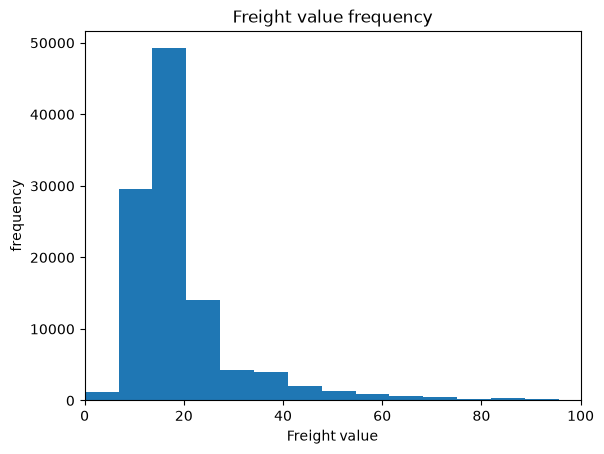

In [23]:
plt.hist(file_cleaned["freight_value"], bins=60)
plt.title("Freight value frequency")
plt.xlim(0,100)
plt.xlabel("Freight value")
plt.ylabel("frequency")
plt.show()

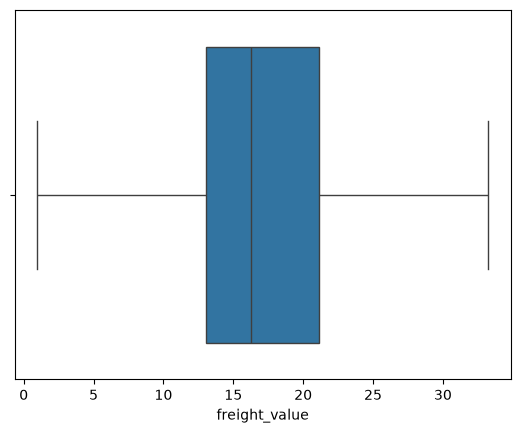

In [24]:
q1 = freight_value_2_1.loc[4, "freight_value"]
q3 = freight_value_2_1.loc[6, "freight_value"]
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
sns.boxplot(data=file_cleaned, x="freight_value", showfliers=False)
plt.show()

**Kết quả và nhận xét:**

**1. Thống kê mô tả**
- Tổng số: 108.937 item.
- Mean: 20,012 BRL; Median: 16,280 BRL.
- 50% giá trị phí nằm trong khoảng 13,080–21,150 BRL.
- Phí thấp nhất: 0,010 BRL; cao nhất: 409,680 BRL.

**2. Histogram**
- Phí vận chuyển tập trung chủ yếu ở các mức thấp.
- Phân phối lệch phải, phù hợp với Mean lớn hơn Median.
- Một số ít item có mức phí cao tạo thành đuôi dài bên phải.

**3. Boxplot và IQR**
- Q1 = 13,080 BRL; Q3 = 21,150 BRL.
- IQR = 8,070 BRL.
- Ngưỡng dưới = 0,975 BRL; ngưỡng trên = 33,255 BRL.
- Phát hiện 11.349 item ngoài ngưỡng IQR, chiếm khoảng 10,42% dữ liệu.
- Các giá trị này là outlier theo quy tắc thống kê, chưa đủ bằng chứng kết luận là lỗi.

**Kết luận:**

<span style="color: red;">Phí vận chuyển phân phối lệch phải</span>
, phần lớn item có mức phí tương đối thấp, trong khi một số item có phí cao hơn đáng kể.

**Quyết định:**

Không loại outlier chỉ dựa vào IQR. Cần tiếp tục kiểm tra mối liên hệ giữa phí với cân nặng, thể tích và khoảng cách vận chuyển để đánh giá liệu những mức phí cao có thể giải thích được hay không.


### 2.2. Phân tích phí vận chuyển theo thời gian

**Mục tiêu:** Kiểm tra sự thay đổi của phí vận chuyển qua các tháng.

**Phương pháp:**
- `groupby()`, `agg()`: Thống kê số item, phí trung bình và trung vị theo tháng.
- Lineplot: Quan sát xu hướng phí vận chuyển theo thời gian.

**Câu hỏi:** Phí vận chuyển có thay đổi đáng kể giữa các tháng không?


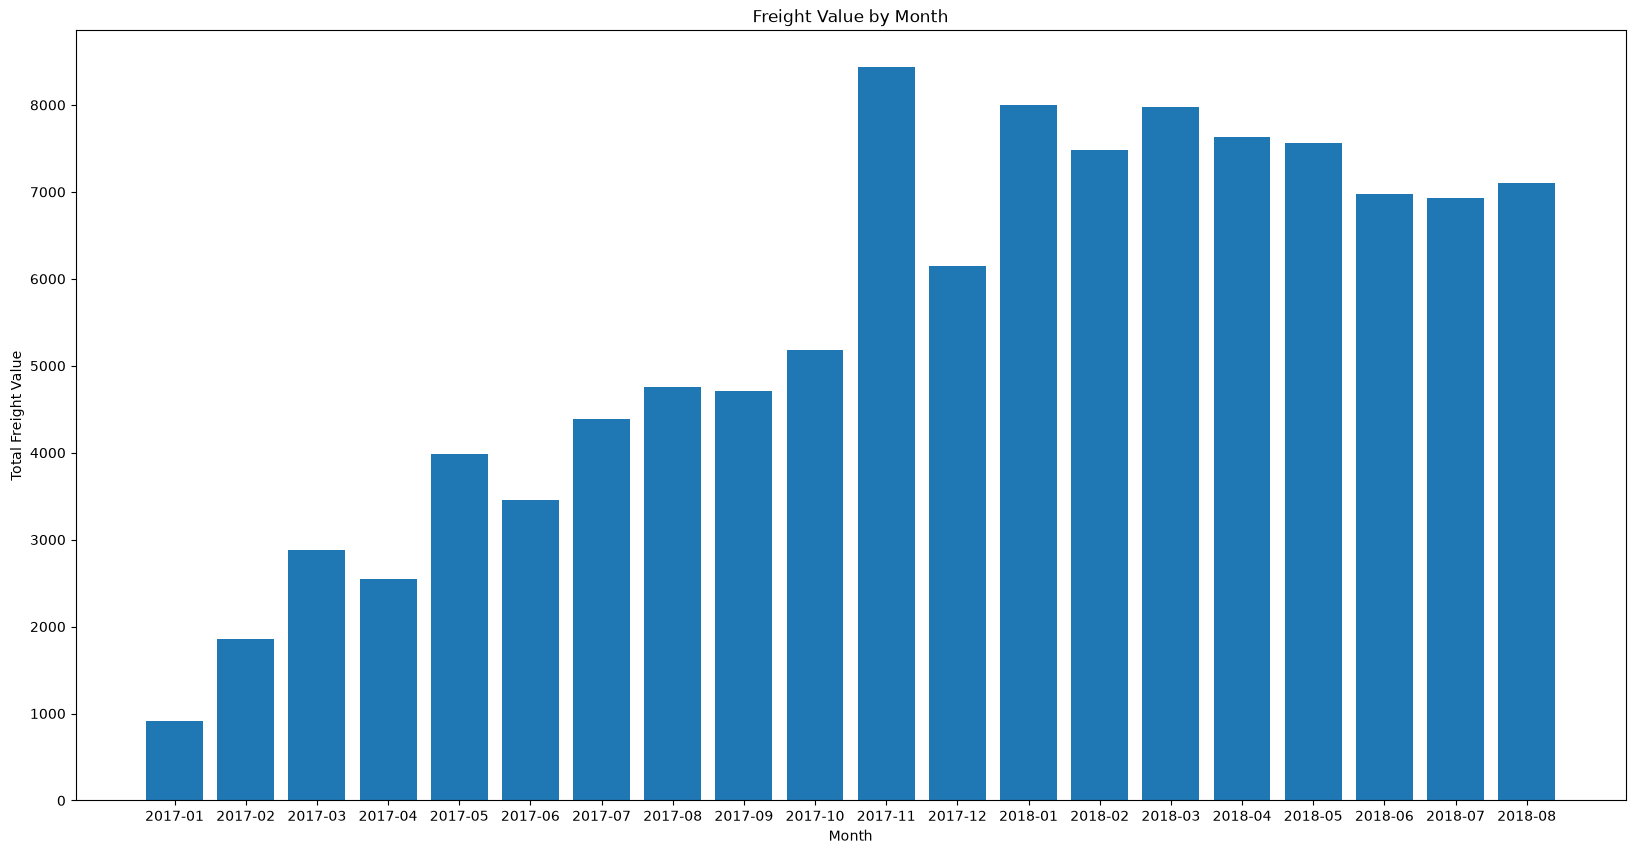

In [25]:
df2_2 = file_cleaned.groupby("month")["freight_value"].count().reset_index()
df2_2 = df2_2.sort_values(by="month", ascending=True)
plt.figure(figsize=(20, 10))
plt.bar(df2_2["month"], df2_2["freight_value"])
plt.xlabel("Month")
plt.ylabel("Total Freight Value")
plt.title("Freight Value by Month")
plt.show()

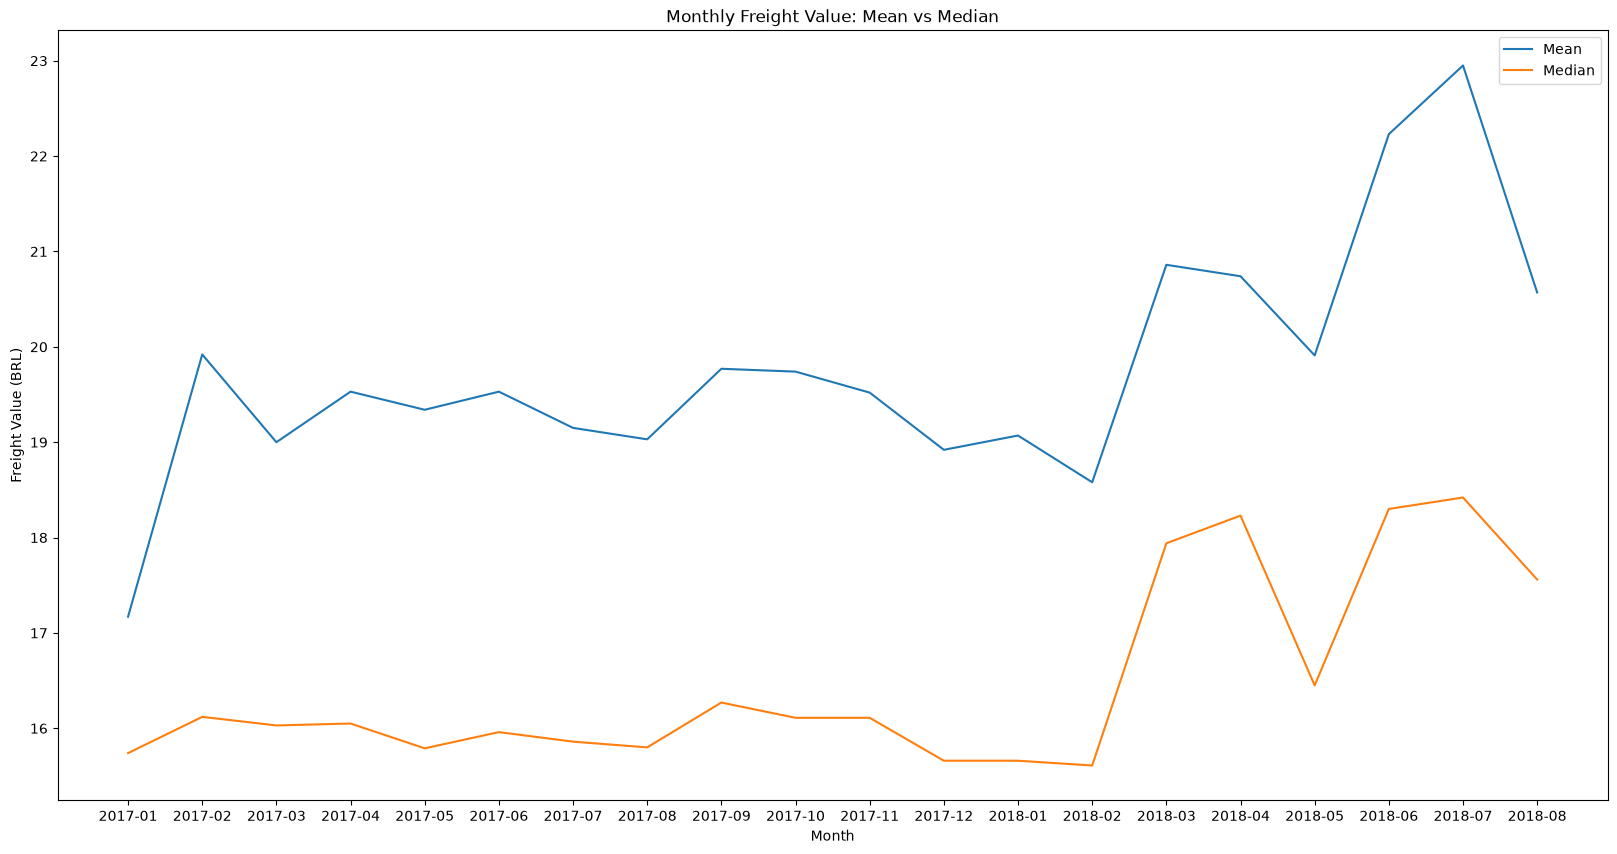

In [26]:
df2_2 = file_cleaned.groupby("month").agg(Mean = ("freight_value","mean"), Median=("freight_value","median")).round(2).reset_index()
plt.figure(figsize=(20,10))
sns.lineplot(data=df2_2, x="month", y="Mean", label="Mean")
sns.lineplot(data=df2_2, x="month", y="Median", label="Median")
plt.title("Monthly Freight Value: Mean vs Median")
plt.xlabel("Month")
plt.ylabel("Freight Value (BRL)")
plt.show()

**Nhận xét:**
- Mean luôn cao hơn Median, phù hợp với phân phối lệch phải đã quan sát ở mục 2.1.
- Trong năm 2017 đến tháng 2/2018, phí trung vị tương đối ổn định, chủ yếu khoảng 15–16 BRL.
- Từ tháng 3/2018, phí trung vị nhìn chung cao hơn, đặc biệt vào tháng 6–7/2018.
- Tháng 7/2018 có Mean = 22,95 BRL và Median = 18,42 BRL.

**Kết luận:** <span style="color:red">Phí vận chuyển điển hình có sự thay đổi theo thời gian</span>, đặc biệt tăng ở một số tháng năm 2018. Tuy nhiên, chưa đủ bằng chứng khẳng định nguyên nhân là thay đổi chính sách giá vận chuyển. Cần phân tích thêm cân nặng, khoảng cách và cơ cấu đơn hàng để giải thích sự khác biệt.

## 3. Phân tích các yếu tố liên quan đến phí vận chuyển ##

**Mục tiêu:** Tìm hiểu vì sao các item có mức freight_value khác nhau, từ đó đề xuất những đặc trưng đáng thử trong Modeling.


### 3.1. Cân nặng và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa cân nặng sản phẩm (`weight_g`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.


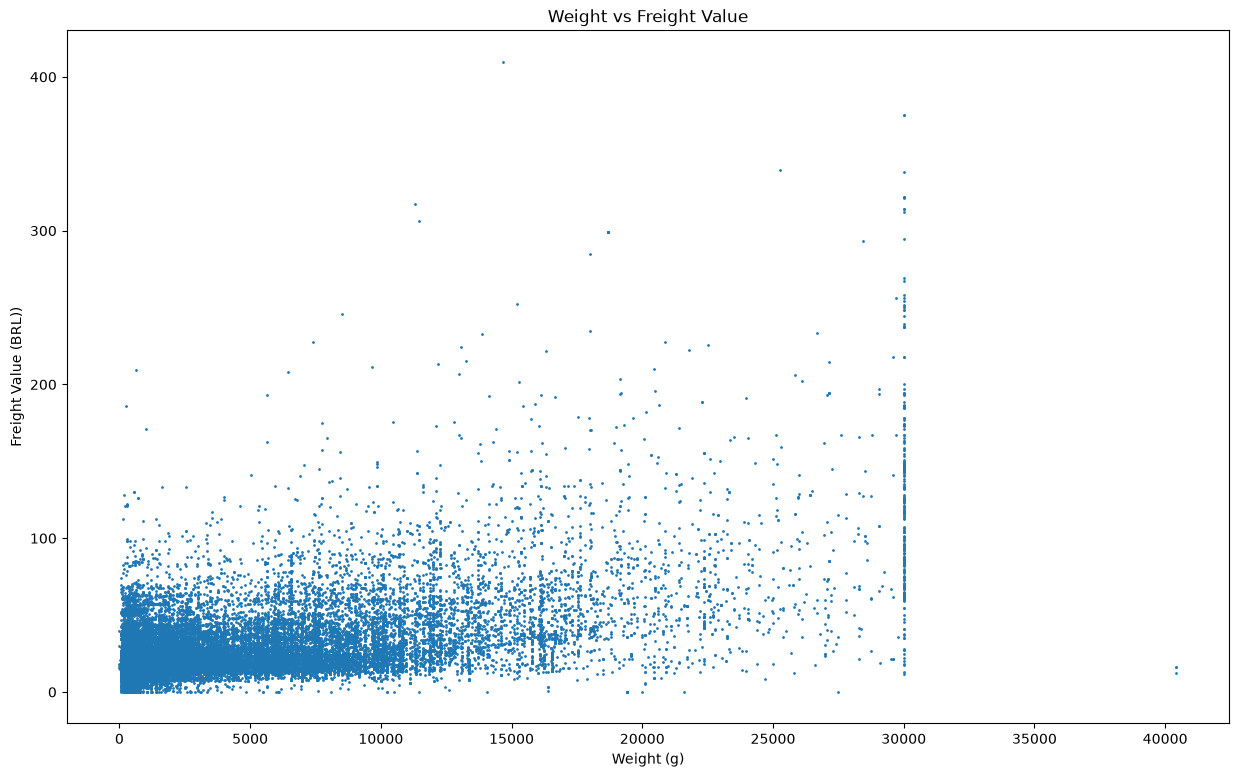

In [27]:
df3_1 = file_cleaned[["weight_g","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_1["weight_g"], df3_1["freight_value"],s=1)
plt.title("Weight vs Freight Value")
plt.xlabel("Weight (g)")
plt.ylabel("Freight Value (BRL))")
plt.show()

In [28]:
cor = df3_1[["weight_g","freight_value"]].corr(method="pearson")
display(cor.round(2))

,weight_g,freight_value
weight_g,1.00,0.61
freight_value,0.61,1.00


**Nhận xét:**
- Pearson ≈ 0,61 cho thấy tương quan tuyến tính dương tương đối mạnh.
- Phí vận chuyển có xu hướng tăng theo cân nặng, nhưng vẫn phân tán đáng kể.
- Xuất hiện nhiều sản phẩm có cân nặng 30.000 g, cần lưu ý khi phân tích.
- Cùng mức cân nặng vẫn có nhiều mức phí khác nhau.

**Kết luận:** Cân nặng có mối liên hệ đáng chú ý với phí vận chuyển và là đặc trưng tiềm năng cho Modeling. Tuy nhiên, chưa thể kết luận quan hệ nhân quả hoặc mức độ cải thiện dự đoán nếu chỉ dựa vào Pearson.

### 3.2. Thể tích và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa thể tích sản phẩm (`volume_cm3`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng giữa thể tích và phí.
- Pearson: Đánh giá mức độ tương quan tuyến tính.

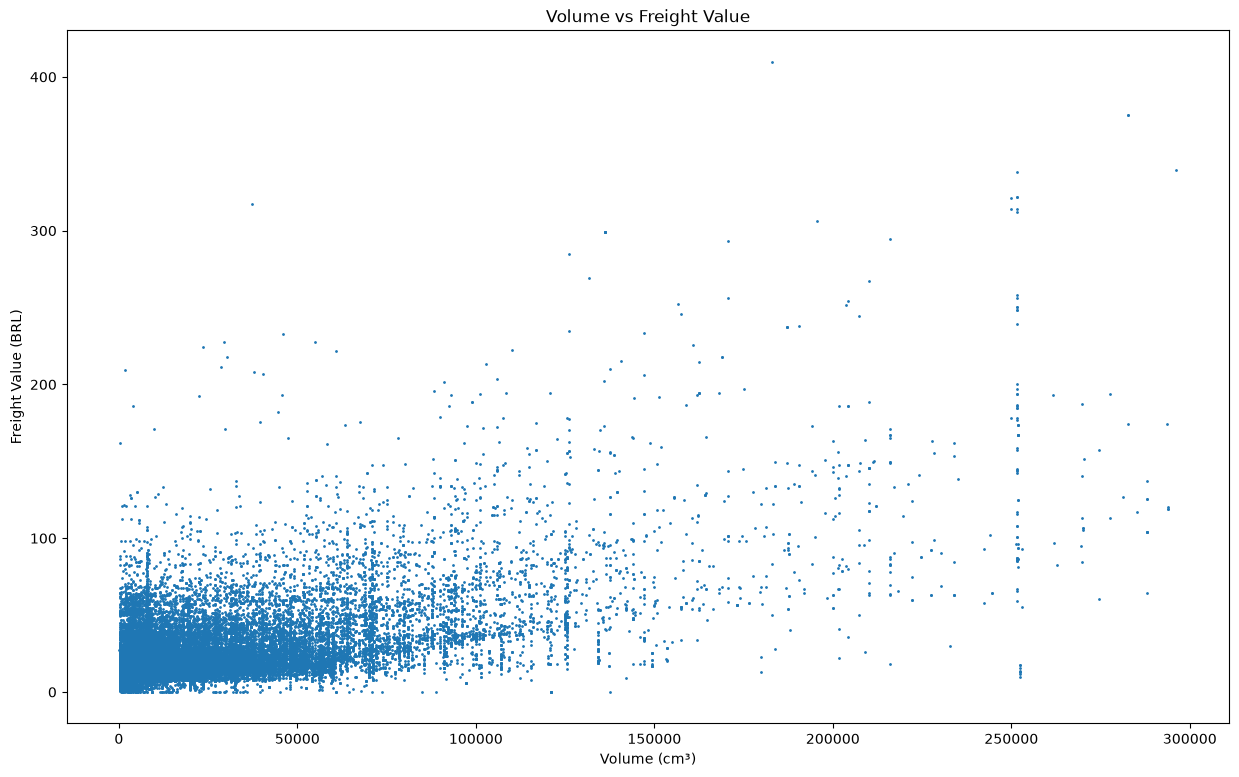

In [29]:
df3_2 = file_cleaned[["volume_cm3","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_2["volume_cm3"], df3_2["freight_value"],s=1)
plt.title("Volume vs Freight Value")
plt.xlabel("Volume (cm³)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [30]:
cor = df3_2[["volume_cm3","freight_value"]].corr(method="pearson")
display(cor.round(2))

,volume_cm3,freight_value
volume_cm3,1.00,0.58
freight_value,0.58,1.00


**Nhận xét:**
- Pearson ≈ 0,58 cho thấy tương quan tuyến tính dương ở mức vừa đến khá.
- Phí có xu hướng tăng theo thể tích nhưng vẫn phân tán đáng kể.
- Xuất hiện nhiều item có thể tích khoảng 250.000 cm³, cần lưu ý khi phân tích.
- Tương quan với phí của thể tích (0,58) thấp hơn một chút so với cân nặng (0,61).

**Kết luận:** Thể tích là đặc trưng tiềm năng cho Modeling. Tuy nhiên, chưa đủ bằng chứng để khẳng định thể tích kém quan trọng hơn cân nặng trong dự đoán


### 3.3. Khoảng cách và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa khoảng cách vận chuyển (`distance_km`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.

**Lưu ý:** `distance_km` là khoảng cách ước tính từ tọa độ, không nhất thiết phản ánh quãng đường vận chuyển thực tế.


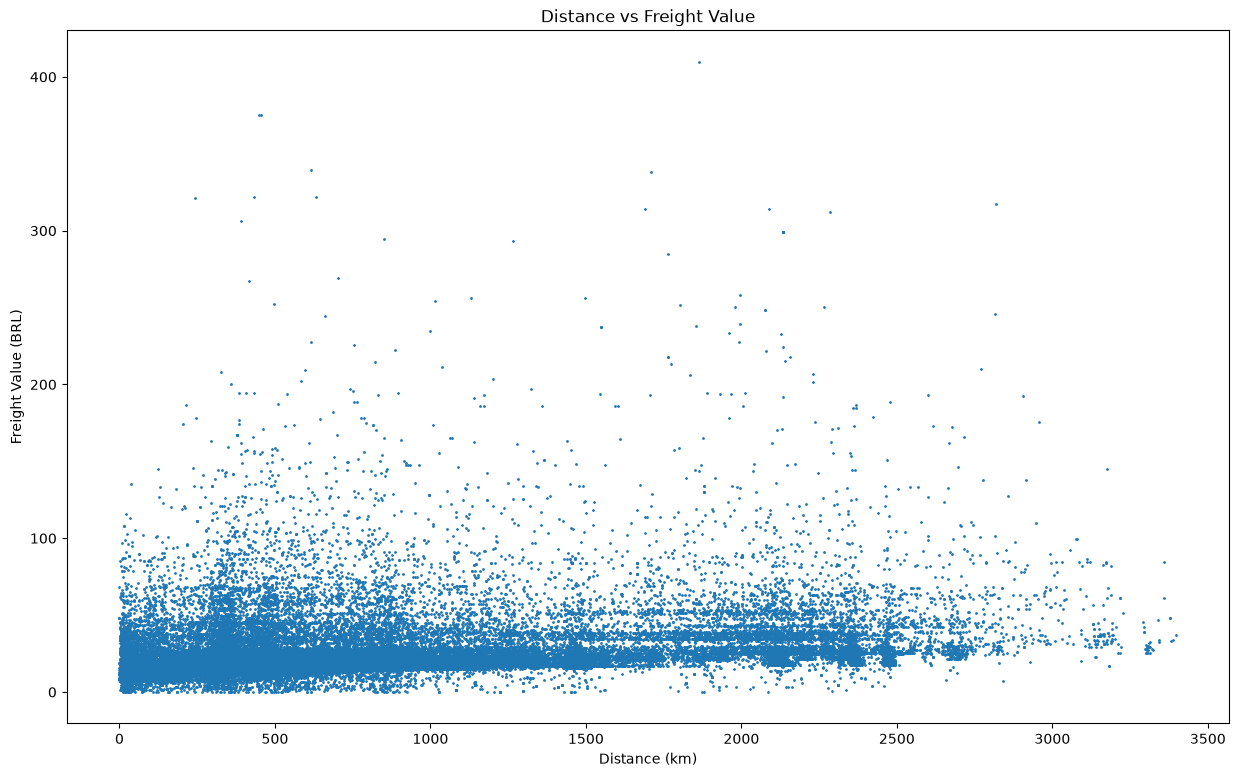

In [31]:
df3_3 = file_cleaned[["distance_km","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_3["distance_km"], df3_3["freight_value"],s=1)
plt.title("Distance vs Freight Value")
plt.xlabel("Distance (km)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [32]:
cor = df3_3[["distance_km","freight_value"]].corr(method="pearson")
display(cor.round(2))

,distance_km,freight_value
distance_km,1.00,0.39
freight_value,0.39,1.00


**Nhận xét:**
- Pearson ≈ 0,39 cho thấy tương quan tuyến tính dương ở mức yếu đến vừa.
- Phí có xu hướng tăng theo khoảng cách nhưng phân tán đáng kể.
- Cùng khoảng cách vẫn xuất hiện nhiều mức phí khác nhau.
- Tương quan thấp hơn cân nặng (0,61) và thể tích (0,58).

**Kết luận:** Khoảng cách là đặc trưng tiềm năng cho Modeling, nhưng chưa thể đánh giá mức độ quan trọng trong dự đoán chỉ dựa vào Pearson. Ngoài ra, `distance_km` là khoảng cách ước tính, không phải quãng đường vận chuyển thực tế.


### 3.4. Giá sản phẩm và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa giá sản phẩm (`price`) và phí vận chuyển (`freight_value`).

**Phương pháp:**
- Scatterplot: Quan sát xu hướng và độ phân tán.
- Pearson: Đánh giá mức độ tương quan tuyến tính.


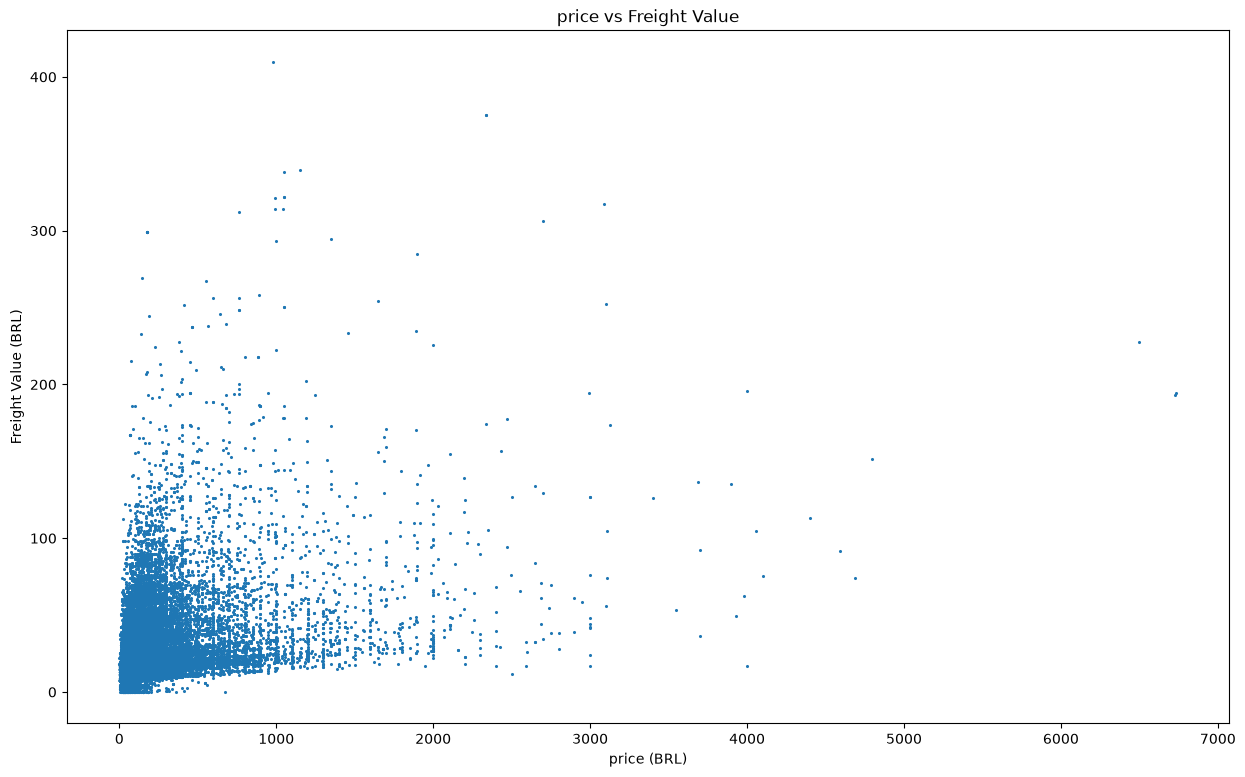

In [33]:
df3_4 = file_cleaned[["price","freight_value"]]
plt.figure(figsize=(15,9))
plt.scatter(df3_4["price"], df3_4["freight_value"],s=1.5,alpha=1)
plt.title("price vs Freight Value")
plt.xlabel("price (BRL)")
plt.ylabel("Freight Value (BRL)")
plt.show()

In [34]:
cor = df3_4[["price","freight_value"]].corr(method="pearson")
display(cor.round(2))

,price,freight_value
price,1.00,0.41
freight_value,0.41,1.00


**Nhận xét:**
- Pearson ≈ 0,41, cho thấy tương quan tuyến tính dương ở mức vừa.
- Phí vận chuyển phân tán đáng kể ở cùng một mức giá.
- Tương quan với phí của giá sản phẩm thấp hơn cân nặng (0,61) và thể tích (0,58).
- Giá có tương quan nhỉnh hơn khoảng cách (0,39), nhưng chưa đủ để kết luận hữu ích hơn khi dự đoán.

**Kết luận:** Giá sản phẩm là đặc trưng tiềm năng cho Modeling. Cần kiểm chứng hiệu quả khi kết hợp với các yếu tố khác, không lựa chọn đặc trưng chỉ dựa vào Pearson.


### 3.5. Khu vực và phí vận chuyển

**Mục tiêu:** So sánh phí vận chuyển giữa các item giao cùng bang (`same_state = 1`) và khác bang (`same_state = 0`).

**Phương pháp:**
- `groupby()` và `agg()`: So sánh số item, Mean và Median.
- Boxplot: Quan sát sự khác biệt về phân phối phí giữa hai nhóm.


In [35]:
df3_5 = file_cleaned.groupby("same_state").agg(Count=("order_id","count"),Mean=("freight_value","mean"),Median=("freight_value","median")).reset_index().round(2)
display(df3_5)

,same_state,Count,Mean,Median
0,0,69330,23.74,18.26
1,1,39607,13.48,12.03


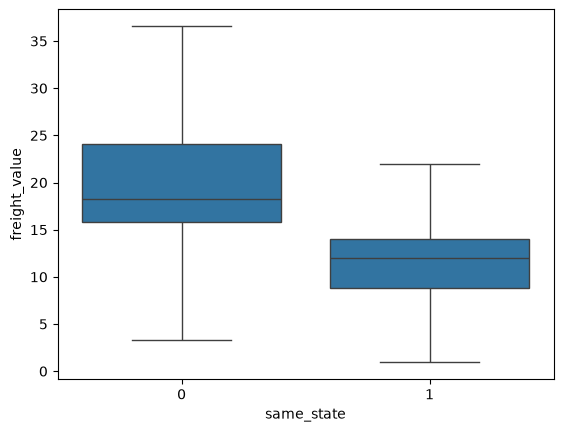

In [36]:
sns.boxplot(data=file_cleaned, x="same_state",y="freight_value", showfliers=False)
plt.show()

**Nhận xét:**
- Khác bang: 69.330 item, Median = 18,26 BRL.
- Cùng bang: 39.607 item, Median = 12,03 BRL.
- Phí trung vị khác bang cao hơn 6,23 BRL.
- Nhóm khác bang có độ phân tán phí lớn hơn.

**Kết luận:** Phí vận chuyển có sự khác biệt đáng kể về mặt mô tả giữa hai nhóm. `same_state` là đặc trưng tiềm năng cho Modeling. Tuy nhiên, sự khác biệt có thể liên quan đến khoảng cách vận chuyển, chưa đủ bằng chứng kết luận quan hệ nhân quả.


### 3.6. Số item trong đơn hàng và phí vận chuyển

**Mục tiêu:** Kiểm tra mối liên hệ giữa số lượng item trong đơn hàng (`order_n_items`) và phí vận chuyển trên mỗi item (`freight_value`).

**Phương pháp:**
- `groupby()` và `agg()`: Thống kê số item, Mean và Median theo quy mô đơn hàng.
- Boxplot: So sánh phân phối phí giữa các nhóm.


In [37]:
df3_6 = file_cleaned.groupby("order_n_items").agg(Count=("order_id","count"),Mean=("freight_value","mean"),Median=("freight_value","median")).reset_index().round(2)
display(df3_6)

,order_n_items,Count,Mean,Median
0,1,85856,20.39,16.47
1,2,14595,18.60,15.65
2,3,3885,18.33,15.79
3,4,1956,18.58,16.11
4,5,950,18.29,15.10
5,6,1134,19.59,15.22
6,7,154,17.67,13.21
7,8,64,22.45,17.67
8,9,27,34.53,30.79
9,10,80,23.11,14.51


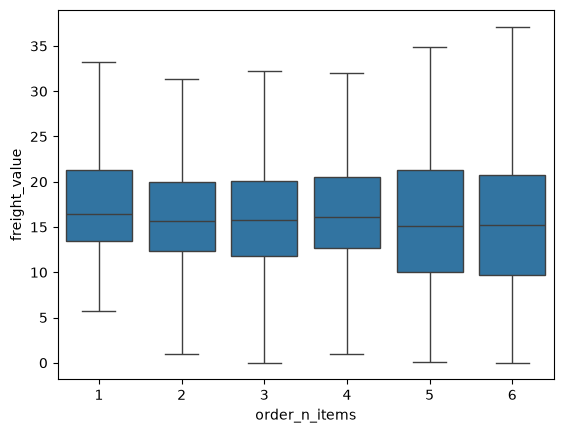

In [38]:
df3_6_boxplot = file_cleaned.loc[file_cleaned["order_n_items"] <= 6]
sns.boxplot(data=df3_6_boxplot,x="order_n_items",y="freight_value",showfliers=False)
plt.show()

In [39]:
actual = file_cleaned.groupby("order_id").size()
expected = file_cleaned.groupby("order_id")["order_n_items"].first()

check = pd.DataFrame({
    "actual": actual,
    "expected": expected
})

check_wrong = check.loc[check["actual"] != check["expected"]]

print("Số đơn không khớp:", len(check_wrong))
display(check_wrong)

Số đơn không khớp: 5


,actual,expected
order_id,,
09224348db675e0c2a00ebe2bd9599db,1,2
2480f727e869fdeb397244a21b721b67,1,2
2868cec2c0d3cc29873e13a46f55f532,1,2
80850824446cd379f755548b967c61b9,1,2
9d302458a5c2070516051da353068870,1,2



**Nhận xét:**
- Đơn có 1 item chiếm phần lớn dữ liệu (85.856/108.937 item).
- Phí trung vị của nhóm 1 item là 16,47 BRL, cao hơn các nhóm 2–6 item (15,10–16,11 BRL).
- Boxplot cho thấy sự khác biệt về trung vị và độ phân tán giữa các nhóm, nhưng chưa có xu hướng giảm phí đều đặn khi số item tăng.
- Các nhóm có nhiều item thường có ít quan sát hơn, cần thận trọng khi so sánh.

**Vấn đề ghi nhận:**
- Có 5 đơn hàng ghi nhận `order_n_items = 2` nhưng chỉ còn 1 item trong bảng Clean.
- Nguyên nhân loại 5 item còn lại chưa được xác định.
 > Ghi nhận và chuyển sang phần 4, chưa tự ý sửa dữ liệu.

**Kết luận:**

Số item trong đơn có mối liên hệ với phí vận chuyển trên mỗi item, nhưng chưa đủ bằng chứng kết luận mua nhiều item giúp giảm phí.

`order_n_items` là đặc trưng tiềm năng cho Modeling. Cần xác minh cách tính và ý nghĩa của cột trước khi sử dụng.



### 3.7. Người bán và phí vận chuyển

**Mục tiêu:** Kiểm tra sự khác biệt về phí vận chuyển giữa các Seller.

**Phương pháp:**
- `groupby()` và `agg()`: So sánh phí vận chuyển giữa các Seller.
- Boxplot: Quan sát phân phối phí theo từng Seller.


In [40]:
df3_7 = file_cleaned.groupby("seller_id").agg(Count=("order_id","count"),Mean=("freight_value","mean"),Median=("freight_value","median")).reset_index()
df3_7 = df3_7.sort_values(by=["Count"], ascending=[False]).head(10)
display(df3_7)

,seller_id,Count,Mean,Median
1176,6560211a19b47992c3666cc44a7e94c0,1991,13.699478,14.100
848,4a3ca9315b744ce9f8e9374361493884,1947,17.612738,15.700
354,1f50f920176fa81dab994f9023523100,1865,18.746874,17.670
2364,cc419e0650a3c5ba77189a1882b7556a,1704,14.452981,14.340
2517,da8622b14eb17ae2831f4ac5b9dab84a,1546,16.074935,15.100
185,1025f0e2d44d7041d6cf58b6550e0bfa,1415,23.732226,17.590
1740,955fee9216a65b617aa5c0531780ce60,1370,18.008307,15.780
1466,7c67e1448b00f6e969d365cea6b010ab,1352,37.806109,33.910
2699,ea8482cd71df3c1969d7b9473ff13abc,1185,14.537241,15.100
1436,7a67c85e85bb2ce8582c35f2203ad736,1152,17.834271,17.275


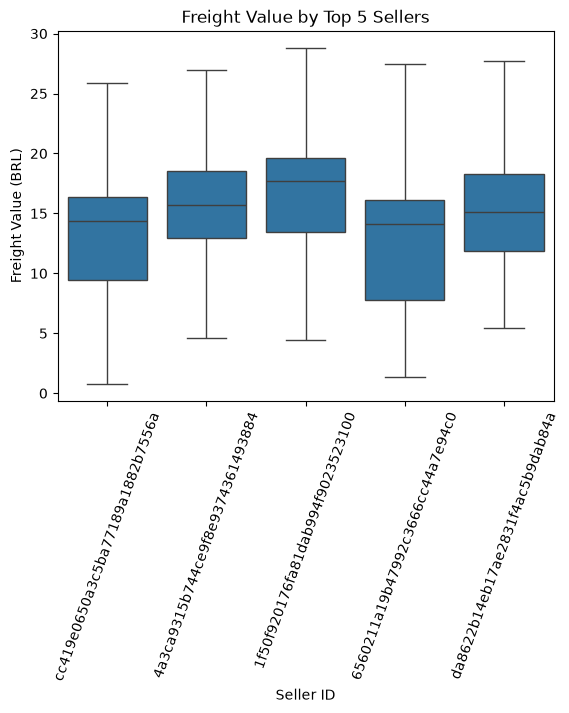

In [41]:
df3_7 = df3_7.head(5)
df3_7_boxplot = file_cleaned[file_cleaned["seller_id"].isin(df3_7["seller_id"])]
sns.boxplot(data=df3_7_boxplot, x="seller_id",y="freight_value",showfliers=False)
plt.xticks(rotation=70)
plt.title("Freight Value by Top 5 Sellers")
plt.xlabel("Seller ID")
plt.ylabel("Freight Value (BRL)")
plt.show()


**Nhận xét:**
- Top 5 Seller có số item lớn nhất được chọn để so sánh.
- Phí trung vị dao động từ 14,10 đến 17,67 BRL.
- Seller `1f50f9...` có phí trung vị cao nhất (17,67 BRL).
- Seller `656021...` có phí trung vị thấp nhất (14,10 BRL) nhưng IQR lớn nhất.
- Phân phối phí khác nhau giữa các Seller, có thể liên quan đến loại sản phẩm, cân nặng và khoảng cách vận chuyển.

**Kết luận:**

Phí vận chuyển có sự khác biệt giữa các Seller được khảo sát. `seller_id` là đặc trưng tiềm năng cho Modeling, nhưng chưa đủ bằng chứng khẳng định Seller trực tiếp quyết định mức phí.

Cần kiểm chứng hiệu quả của đặc trưng này khi kết hợp với các yếu tố khác.



### 3.8. Danh mục sản phẩm và phí vận chuyển

**Mục tiêu:** Kiểm tra sự khác biệt về phí vận chuyển giữa các danh mục sản phẩm (`category`).

**Phương pháp:**
- `groupby()` và `agg()`: Thống kê số item, Mean và Median theo danh mục.
- Boxplot: So sánh phân phối phí giữa các danh mục phổ biến.


In [42]:
df3_8 = file_cleaned.groupby("category").agg(Count=("order_id","count"),Mean=("freight_value","mean"),Median=("freight_value","median")).round(2).reset_index()
df3_8 = df3_8.sort_values(by="Count", ascending=False).head(10)
display(df3_8)

,category,Count,Mean,Median
7,bed_bath_table,10901,18.43,16.19
43,health_beauty,9394,18.92,15.79
65,sports_leisure,8398,19.36,16.25
39,furniture_decor,7979,20.89,16.43
15,computers_accessories,7611,18.83,15.98
49,housewares,6765,21.02,16.76
71,watches_gifts,5621,17.37,16.01
68,telephony,4394,15.64,15.10
42,garden_tools,4196,22.94,17.67
5,auto,4121,21.86,17.60


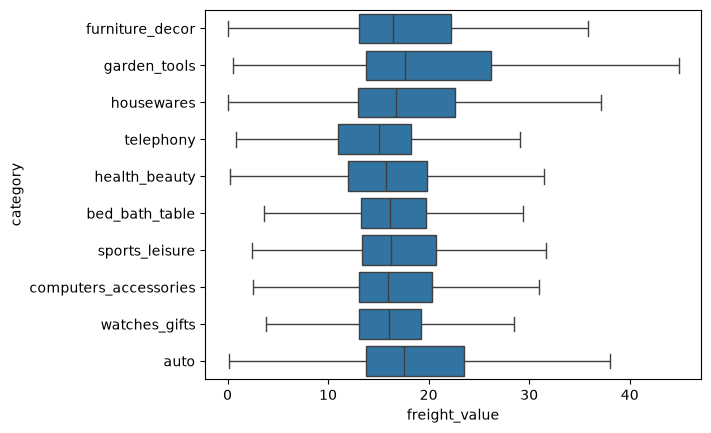

In [43]:
df3_8_boxplot = file_cleaned[file_cleaned["category"].isin(df3_8["category"])]
sns.boxplot(data=df3_8_boxplot, x="freight_value", y="category",showfliers=False)
plt.show()

**Nhận xét:**
- Top 10 danh mục phổ biến cho thấy mức phí vận chuyển có sự khác biệt giữa các nhóm sản phẩm.
- `garden_tools` và `auto` có mức phí vận chuyển điển hình cao hơn nhiều danh mục còn lại.
- `telephony` có mức phí điển hình thấp nhất trong nhóm khảo sát.
- `housewares` và `furniture_decor` cũng có mức phí tương đối cao.
- Độ phân tán phí vận chuyển khác nhau giữa các danh mục, cho thấy cùng một danh mục vẫn có nhiều mức phí khác nhau.

**Kết luận:**

Danh mục sản phẩm có liên hệ với phí vận chuyển. `category` là đặc trưng tiềm năng cho Modeling vì các nhóm sản phẩm khác nhau có mức phí vận chuyển khác nhau về mặt mô tả.

Tuy nhiên, chưa đủ bằng chứng để kết luận chính danh mục trực tiếp quyết định mức phí, vì sự khác biệt có thể còn liên quan đến cân nặng, thể tích và khoảng cách vận chuyển.



### 3.9. Tổng hợp tương quan giữa các đặc trưng

**Mục tiêu:** Đánh giá tương quan tuyến tính giữa các đặc trưng số và phí vận chuyển, đồng thời kiểm tra mối liên hệ giữa các đặc trưng.

**Phương pháp:** Pearson Correlation và Heatmap.

**Các biến:** `weight_g`, `volume_cm3`, `distance_km`, `price`, `freight_value`.



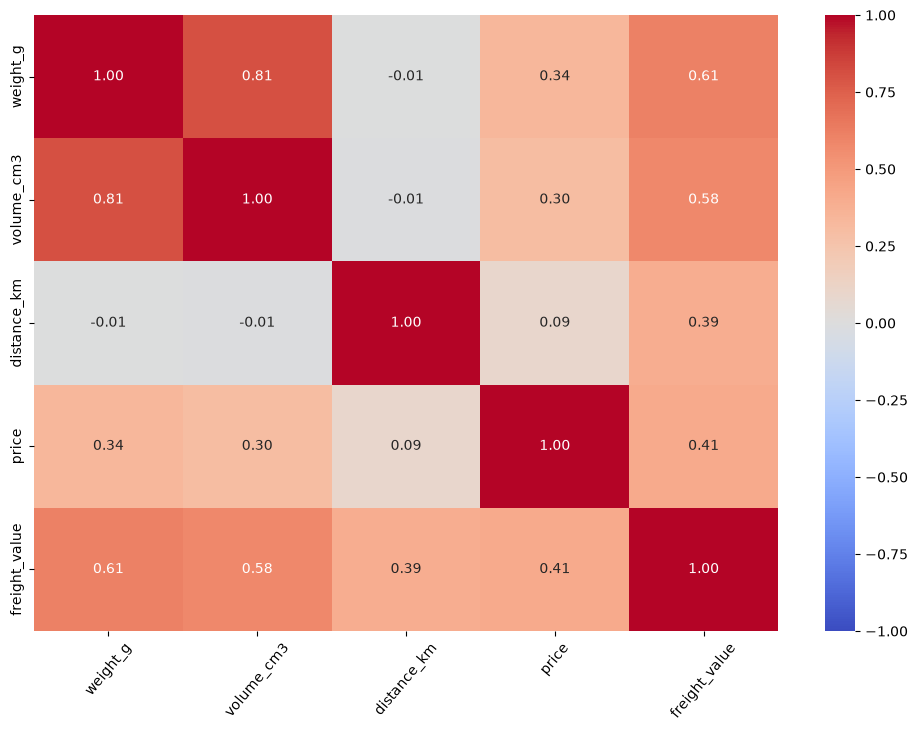

In [44]:
cols = ["weight_g", "volume_cm3", "distance_km", "price", "freight_value"]
corr = file_cleaned[cols].corr(method="pearson")

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",vmin=-1, vmax=1)
plt.xticks(rotation=50)
plt.show()


**Nhận xét:**
- Cả 4 đặc trưng số đều có tương quan tuyến tính dương với `freight_value`.
- `weight_g` (0,61) và `volume_cm3` (0,58) có tương quan với phí cao hơn `price` (0,41) và `distance_km` (0,39).
- Cân nặng và thể tích tương quan mạnh với nhau (0,81), cho thấy khả năng chồng lặp thông tin.
- Khoảng cách gần như không có tương quan tuyến tính với cân nặng và thể tích (-0,01), nhưng vẫn có tương quan dương với phí (0,39).

**Kết luận:**

Cân nặng, thể tích, khoảng cách và giá sản phẩm đều là những đặc trưng tiềm năng cho Modeling.

Cần kiểm chứng hiệu quả khi kết hợp các đặc trưng, đặc biệt là cân nặng và thể tích do có tương quan cao. Không loại đặc trưng chỉ dựa trên Pearson.

Các biến phân loại như `same_state`, `seller_id`, `category` và `order_n_items` cũng cho thấy sự khác biệt về phí giữa các nhóm trong các phân tích trước, cần tiếp tục đánh giá khi Modeling.



### 3.10. Tổng kết các yếu tố liên quan đến phí vận chuyển

**Mục tiêu:** Tổng hợp các phát hiện EDA, đánh giá mối liên hệ giữa các đặc trưng với `freight_value` và đề xuất hướng thử nghiệm cho Modeling.

#### 1. Bảng tổng hợp kết quả EDA

| Đặc trưng | Bằng chứng EDA | Nhận xét |
|---|---|---|
| `weight_g` | Pearson = 0,61 | Tương quan dương tương đối mạnh với phí. |
| `volume_cm3` | Pearson = 0,58 | Tương quan dương; có thể phản ánh mức độ cồng kềnh. |
| `distance_km` | Pearson = 0,39 | Tương quan dương, nhưng khoảng cách chỉ là ước tính. |
| `price` | Pearson = 0,41 | Có tương quan dương, nhưng chưa rõ mối liên hệ độc lập với cân nặng và thể tích. |
| `same_state` | Median cùng bang: 12,03 BRL; khác bang: 18,26 BRL | Phí khác nhau giữa hai nhóm; có thể liên quan đến khoảng cách. |
| `order_n_items` | Median nhóm 1 item: 16,47 BRL; nhóm 2–6 item: 15,10–16,11 BRL | Có sự khác biệt, chưa chứng minh mua nhiều làm giảm phí. |
| `seller_id` | Median Top 5: 14,10–17,67 BRL | Phí khác nhau giữa các Seller được khảo sát. |
| `category` | Median Top 10: 15,10–17,67 BRL | Phí khác nhau giữa các danh mục phổ biến. |

#### 2. Những phát hiện quan trọng

**Các đặc trưng số:**
- Cân nặng và thể tích có tương quan tuyến tính với phí cao nhất trong 4 biến số được khảo sát.
- Cân nặng và thể tích tương quan mạnh với nhau (r = 0,81), cho thấy khả năng chồng lặp thông tin.
- Khoảng cách gần như không tương quan tuyến tính với cân nặng và thể tích (r ≈ -0,01), nhưng vẫn có tương quan dương với phí (r = 0,39). Vì vậy, khoảng cách có thể bổ sung thông tin riêng.

**Các đặc trưng phân loại:**
- `same_state`, `seller_id`, `category` và các nhóm `order_n_items` cho thấy sự khác biệt về phân phối phí.
- Những khác biệt này chưa chứng minh quan hệ nhân quả và có thể chịu ảnh hưởng từ các đặc trưng khác.

**Hạn chế cần lưu ý:**
- Pearson chỉ đo tương quan tuyến tính, không phản ánh đầy đủ khả năng dự đoán.
- `seller_id` có nhiều giá trị khác nhau; mô hình cần có phương án xử lý Seller chưa từng xuất hiện.
- `distance_km` là khoảng cách ước tính, không phải quãng đường giao hàng thực tế.
- Phát hiện 5 đơn hàng có `order_n_items` không khớp số item còn lại sau Cleaning. Cần kiểm chứng trước khi chốt đặc trưng.

#### 3. Đề xuất cho Modeling

- **Nhóm vật lý:** Thử `weight_g`, `volume_cm3` và kiểm tra giá trị bổ sung khi kết hợp hai biến.
- **Nhóm địa lý:** Thử `distance_km`, `same_state` để đánh giá thông tin vận chuyển.
- **Nhóm sản phẩm và đơn hàng:** Thử `price`, `category`, `order_n_items`.
- **Nhóm người bán:** Đánh giá khả năng bổ sung của `seller_id`, đồng thời xử lý Seller mới.

Nên so sánh các tổ hợp đặc trưng có cơ sở từ EDA trên cùng quy trình đánh giá, ưu tiên MAE và bổ sung RMSE, R². Cần chia dữ liệu phù hợp theo thời gian và tránh sử dụng thông tin không có sẵn tại thời điểm dự đoán.

#### 4. Kết luận

EDA cho thấy phí vận chuyển có mối liên hệ với nhiều đặc trưng vật lý, địa lý, sản phẩm và đơn hàng.

Cân nặng và thể tích có tương quan tuyến tính nổi bật với phí, trong khi khoảng cách có khả năng bổ sung thông tin khác với hai đặc trưng này. Các biến phân loại cũng cho thấy sự khác biệt đáng chú ý giữa các nhóm.

**Không loại hoặc xếp hạng mức độ quan trọng của đặc trưng chỉ dựa trên Pearson hay chênh lệch phí giữa các nhóm.**

Các phát hiện hiện tại là cơ sở đề xuất đặc trưng. Hiệu quả thực tế của từng đặc trưng và tổ hợp cần được kiểm chứng tại bước Modeling thông qua khả năng dự đoán trên dữ liệu chưa dùng để huấn luyện.


## 4. Kiểm chứng các vấn đề còn tồn đọng ##

### 4.1. Kiểm chứng danh mục `unknown`

**Mục tiêu:** Đánh giá tính hợp lý của việc giữ các item thiếu thông tin danh mục sau Cleaning.

**Câu hỏi:**
- Có bao nhiêu item thuộc nhóm `unknown`?
- Nhóm này chiếm bao nhiêu phần trăm dữ liệu?
- Các item `unknown` còn đủ thông tin vật lý và vận chuyển không?
- Việc loại nhóm này có thể làm mất thông tin hữu ích không?


In [45]:
unknown_items = file_cleaned[file_cleaned["category"] == "unknown"].shape[0]
df4_1 = pd.DataFrame({
    "Check" : ["Unknown items","Unknown (%)"],
    "Value" : [unknown_items,unknown_items / file_cleaned.shape[0] * 100]
}).round(2)

display(df4_1)

,Check,Value
0,Unknown items,1532.00
1,Unknown (%),1.41



**Nhận xét:**
- Có 1.532/108.937 item thuộc danh mục `unknown`, chiếm 1,41% dữ liệu sau Cleaning.
- Đây là nhóm có tỷ lệ tương đối nhỏ, nhưng chưa đủ bằng chứng để quyết định loại bỏ.
- Cần đối chiếu các đặc trưng và phí vận chuyển của nhóm `unknown` với nhóm có danh mục xác định.
